<a href="https://colab.research.google.com/github/magness69/boston-house-prices/blob/main/boston_house_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting house prices (Boston dataset)

**Question:** which regression method predicts the median house price (`MEDV`) best?

I compare 5 models on the same split: linear, polynomial, Ridge, Lasso, and PCA + linear.
The best one is chosen on the validation set, and the test set is used only once at the end.

In [3]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_squared_error

## 1. Data

In [4]:
# on Kaggle the csv is in /kaggle/input, otherwise put it next to the notebook
files = glob.glob("/content/boston.csv") + glob.glob("*.csv")
df = pd.read_csv(files[0])
print(files[0], df.shape)
df.head()

/content/boston.csv (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [5]:
print(df.isna().sum())
df.describe()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


## 2. Cleaning

- Missing values (if any) are replaced by the column median.
- I drop column `B`: it is built from the racial make-up of each town, and it is not a good feature to use for predicting prices.

In [6]:
df = df.drop(columns=["B"])
df = df.fillna(df.median())

X = df.drop(columns=["MEDV"])
y = df["MEDV"]

## 3. Split and scaling (60% train, 20% validation, 20% test)

In [7]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=0)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=0)

scaler = StandardScaler()
Xtr = scaler.fit_transform(X_train)
Xva = scaler.transform(X_val)
Xte = scaler.transform(X_test)

# polynomial features (degree 2)
poly = PolynomialFeatures(2, include_bias=False)
Xtr_p = poly.fit_transform(Xtr)
Xva_p = poly.transform(Xva)
Xte_p = poly.transform(Xte)

# PCA: keep 95% of the variance
pca = PCA(0.95)
Xtr_pca = pca.fit_transform(Xtr)
Xva_pca = pca.transform(Xva)
Xte_pca = pca.transform(Xte)
print("PCA components kept:", pca.n_components_)

PCA components kept: 9


## 4. Choosing alpha for Ridge and Lasso (on validation)

In [8]:
alphas = [0.01, 0.1, 1, 10, 100]

def best_alpha(Model):
    scores = []
    for a in alphas:
        m = Model(alpha=a, max_iter=10000) if Model is Lasso else Model(alpha=a)
        m.fit(Xtr_p, y_train)
        scores.append(r2_score(y_val, m.predict(Xva_p)))
    return alphas[int(np.argmax(scores))]

a_ridge = best_alpha(Ridge)
a_lasso = best_alpha(Lasso)
print("Ridge alpha:", a_ridge, "| Lasso alpha:", a_lasso)

Ridge alpha: 0.1 | Lasso alpha: 0.01


## 5. Comparing the models

In [9]:
models = {
    "Linear":        (LinearRegression(),                    Xtr,     Xva,     Xte),
    "Polynomial":    (LinearRegression(),                    Xtr_p,   Xva_p,   Xte_p),
    "Ridge (poly)":  (Ridge(alpha=a_ridge),                  Xtr_p,   Xva_p,   Xte_p),
    "Lasso (poly)":  (Lasso(alpha=a_lasso, max_iter=10000),  Xtr_p,   Xva_p,   Xte_p),
    "PCA + linear":  (LinearRegression(),                    Xtr_pca, Xva_pca, Xte_pca),
}

rows = []
for name, (model, tr, va, te) in models.items():
    model.fit(tr, y_train)
    pred = model.predict(va)
    rows.append([name, r2_score(y_val, pred), np.sqrt(mean_squared_error(y_val, pred))])

results = pd.DataFrame(rows, columns=["model", "val_R2", "val_RMSE"]).sort_values("val_R2", ascending=False)
results.round(3)

,model,val_R2,val_RMSE
2,Ridge (poly),0.759,4.387
3,Lasso (poly),0.758,4.397
1,Polynomial,0.754,4.429
0,Linear,0.639,5.370
4,PCA + linear,0.604,5.620


## 6. Best model on the test set

Best model: Ridge (poly)
Test R2  : 0.885
Test RMSE: 3.13


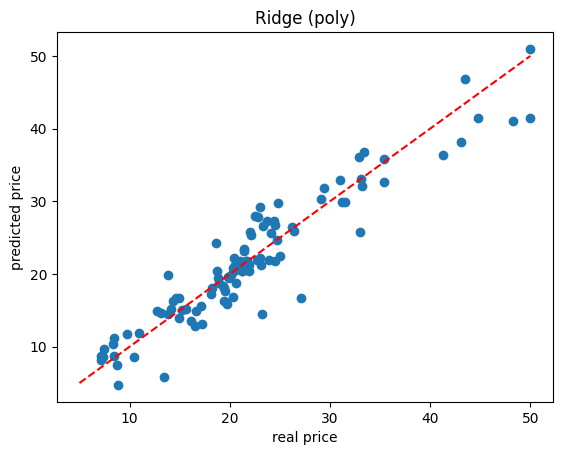

In [10]:
best = results.iloc[0]["model"]
model, tr, va, te = models[best]
pred = model.predict(te)

print("Best model:", best)
print("Test R2  :", round(r2_score(y_test, pred), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

plt.scatter(y_test, pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("real price")
plt.ylabel("predicted price")
plt.title(best)
plt.show()

## Conclusion

The best model on validation was [model] (R² = [x], RMSE = [y]). On the test set it got R² = [x] and RMSE = [y]. The gap between validation and test is [small / noticeable], which suggests [it generalizes well / some overfitting, since the dataset has only 506 houses]. Polynomial features [helped / did not help] compared to plain linear regression, and Ridge/Lasso [reduced overfitting / changed little]. PCA reduced the data to [n] components but [kept / lost] some accuracy. With more time I would try [cross-validation / a tree-based model like random forest / more feature engineering].